In [17]:
import numpy as np
import healpy as hp
import matplotlib.pylab as plt
%matplotlib inline
import rubin_sim.splat as splat
import copy 

import sqlite3
import pandas as pd
from os.path import basename

import glob

In [18]:
# Define a report element that we want to run. Needs branch maf-proto of rubin_sim to run
class CountsTimeElement(splat.BaseReportElement):
    def compute_elements(self,visits_df=None, visits_array=None, nside=32, band=None):
        metrics = []
        infos = []
        times = np.arange(3653)
        metrics.append(splat.AccumulateCountMetric(times))
        info = {"data_source": self.run_name}
        if band is None:
            info["observations_subset"] = "\nNo ToO, No DDf, expt > 20"
        else:
            info["observations_subset"] =  band + "\nNo ToO, No DDf, expt > 20"

        # Number of visits
        temp_info = copy.copy(info)
        temp_info["group"] = "Basics"
        temp_info["subgroup"] = "Counts"
        infos.append(temp_info)
       
        is_too = np.array(["ToO" in note for note in visits_array["scheduler_note"]])
        is_ddf = np.array(["DD" in note for note in visits_array["scheduler_note"]])

        if band is None:
            indx = np.where((~is_too) & (~is_ddf) & (visits_array["visitExposureTime"] > 20))
        else:
            indx = np.where((~is_too) & (~is_ddf) & (visits_array["visitExposureTime"] > 20) & (visits_array["band"] == band))
        sub_data = visits_array[indx]
        sl = splat.Slicer(nside=nside, missing=0)
        hp_arrays, infos = sl(sub_data, metrics, info=infos)

        return hp_arrays, infos, None


In [19]:
db_files = ['baseline_v5.3.7_10yrs.db', 
            #'fp_mod_8_v5.3.6_10yrs.db',
            'fp_mod_9_v5.3.6_10yrs.db',
            #'fp_mod_10_v5.3.6_10yrs.db',
            "fp_refine_1_v5.3.6_10yrs.db",
            "fp_refine_2_v5.3.6_10yrs.db"
            ]

In [20]:
data_list = []
info_list = []

u_data_list = []
u_info_list = []

r_data_list = []
r_info_list = []

for filename in db_files:
    element = CountsTimeElement(observations=filename)
    hp_arrays, infos, summary = element()
    data_list.append(hp_arrays)
    info_list.append(infos)

    hp_arrays, infos, summary = element(band="u")
    u_data_list.append(hp_arrays)
    u_info_list.append(infos)

    hp_arrays, infos, summary = element(band="r")
    r_data_list.append(hp_arrays)
    r_info_list.append(infos)
    
    

# Year 1
All plots No ToOs, No DDfs, expt > 20. All bands unless marked.

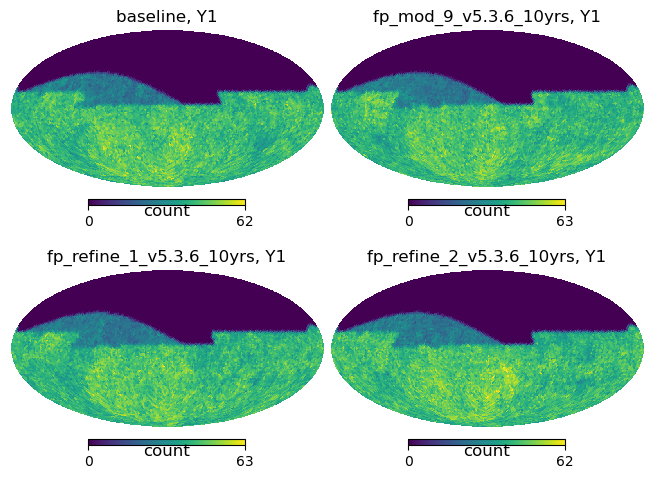

In [21]:
for i, (data, info) in enumerate(zip(data_list, info_list)):
    hp.mollview(data[:,365], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y1",
                unit="count", sub=(2,2, i+1))

# Year 2

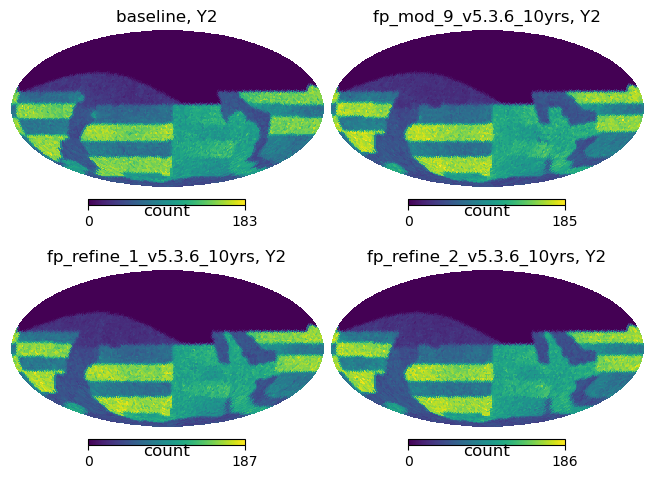

In [22]:
for i, (data, info) in enumerate(zip(data_list, info_list)):
    hp.mollview(data[:,365*2], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y2",
                unit="count", sub=(2,2, i+1))

# Year 4

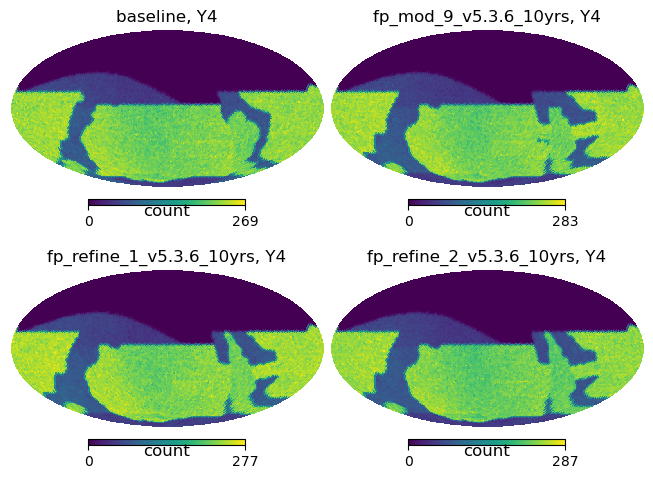

In [23]:
for i, (data, info) in enumerate(zip(data_list, info_list)):
    hp.mollview(data[:,365*4], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y4" ,
                unit="count", sub=(2,2, i+1))

# Year 10



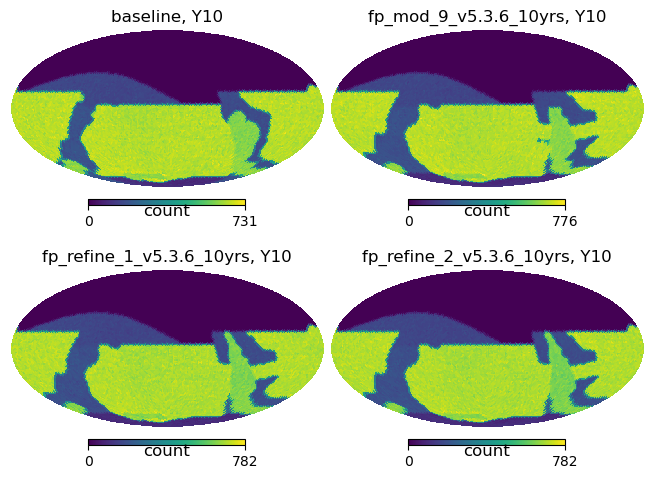

In [24]:
for i, (data, info) in enumerate(zip(data_list, info_list)):
    hp.mollview(data[:,365*10], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y10",
                unit="count", sub=(2,2, i+1))

# Year 3 in u-band

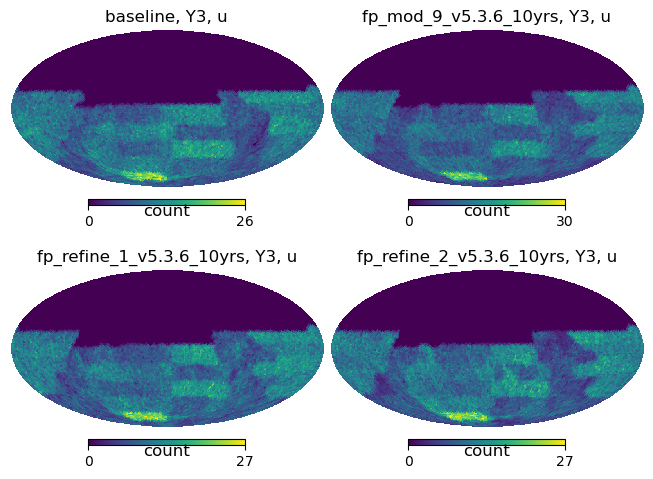

In [25]:
year = 3
for i, (data, info) in enumerate(zip(u_data_list, u_info_list)):
    hp.mollview(data[:,365*year], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y%i" % year + ', u',
                unit="count", sub=(2,2, i+1))

# Year 10 in u band

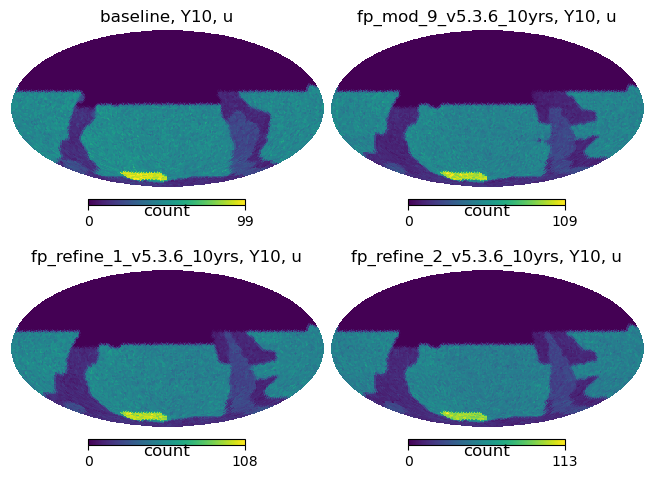

In [26]:
year = 10
for i, (data, info) in enumerate(zip(u_data_list, u_info_list)):
    hp.mollview(data[:,365*year], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y%i" % year + ', u',
                unit="count", sub=(2,2, i+1))

# Year 10 in r band

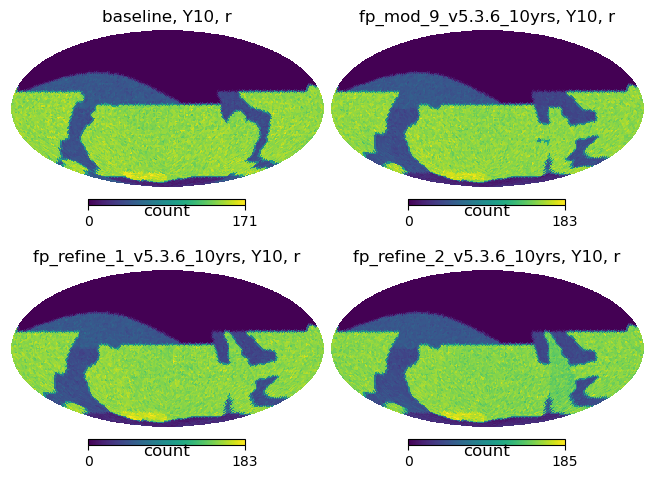

In [27]:
year = 10
for i, (data, info) in enumerate(zip(r_data_list, r_info_list)):
    hp.mollview(data[:,365*year], title=info["data_source"].replace("_v5.3.7_10yrs", "") + ", " +  "Y%i" % year + ', r',
                unit="count", sub=(2,2, i+1))

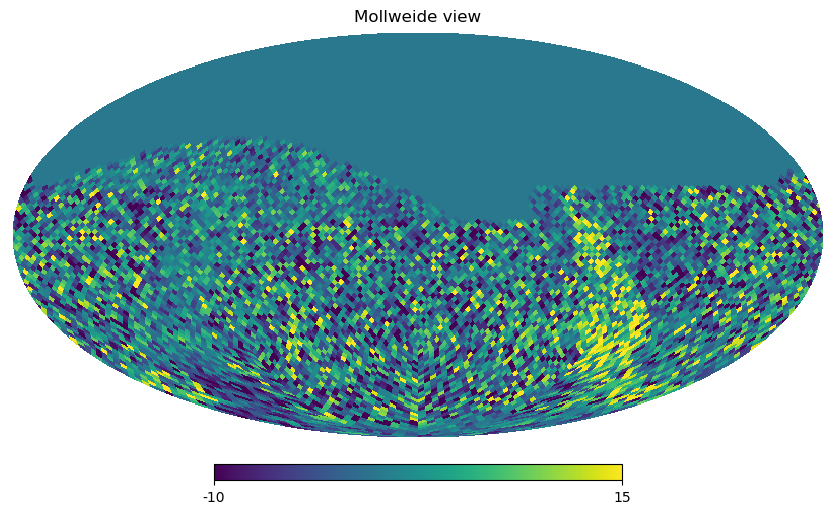

In [32]:
# Did we really turn down the number of r-band visits in bulgy? Yes, looks like it, but not much
hp.mollview(r_data_list[2][:,-1] - r_data_list[3][:,-1], min=-10, max=15)